# L1-based models for sparse signals: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/linear_model/plot_lasso_and_elasticnet.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/linear_model/plot_lasso_and_elasticnet.html)).

**Scenario:** a synthetic signal built from 100 sinusoidal, correlated features, of which 10 are informative, plus Gaussian noise (`RandomState(0)`, 50 samples). The first 25 samples train and the last 25 test (`shuffle=False`). The example fits `Lasso(alpha=0.14)`, `ARDRegression()` and `ElasticNet(alpha=0.08, l1_ratio=0.5)`, then compares their test R² and their coefficients with the ground truth.

**Adaptations:**
- The data is generated by the official NumPy code and shared with Mojo.
- **`ARDRegression` is not implemented in Moxie** (deferred in `families/linear_model/docs/coverage.md`). The reference still runs it, and an expect-fail cell shows Moxie's failure.
- The example's seaborn/pandas heatmap is drawn with `matplotlib.imshow`, because seaborn is not in the environment. Fit timings are printed but not compared.
- Beyond the example, the notebook also checks:
  - Float32 fits of both estimators against sklearn on Float32 data;
  - `set_params(alpha=...)` followed by a refit;
  - a `warm_start=True` refit.
- Single-target `intercept_` is a length-one array, and `n_iter_`/`dual_gap_` are always arrays. Both are documented in `families/linear_model/algorithms/elastic_net/docs/api.md`.

**Determinism:** deterministic. The data is seeded and cyclic coordinate descent is deterministic.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("linear_model/plot_lasso_and_elasticnet")

## 1. scikit-learn (Python reference, official code)

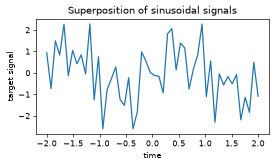

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.RandomState(0)
n_samples, n_features, n_informative = 50, 100, 10
time_step = np.linspace(-2, 2, n_samples)
freqs = 2 * np.pi * np.sort(rng.rand(n_features)) / 0.01
X = np.zeros((n_samples, n_features))
for i in range(n_features):
    X[:, i] = np.sin(freqs[i] * time_step)
idx = np.arange(n_features)
true_coef = (-1) ** idx * np.exp(-idx / 10)
true_coef[n_informative:] = 0  # sparsify coef
y = np.dot(X, true_coef)
for i in range(n_features):
    X[:, i] = np.sin(freqs[i] * time_step + 2 * (rng.random_sample() - 0.5))
    X[:, i] += 0.2 * rng.normal(0, 1, n_samples)
y += 0.2 * rng.normal(0, 1, n_samples)

plt.figure(figsize=(5, 2.5), dpi=60)
plt.plot(time_step, y)
plt.ylabel("target signal")
plt.xlabel("time")
_ = plt.title("Superposition of sinusoidal signals")
plt.show()

In [3]:
from time import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import ARDRegression, ElasticNet, Lasso
from sklearn.metrics import r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, shuffle=False)

t0 = time()
lasso = Lasso(alpha=0.14).fit(X_train, y_train)
print(f"Lasso fit done in {(time() - t0):.3f}s")
y_pred_lasso = lasso.predict(X_test)
r2_score_lasso = r2_score(y_test, y_pred_lasso)
print(f"Lasso r^2 on test data : {r2_score_lasso:.3f}")

t0 = time()
ard = ARDRegression().fit(X_train, y_train)
print(f"ARD fit done in {(time() - t0):.3f}s")
y_pred_ard = ard.predict(X_test)
r2_score_ard = r2_score(y_test, y_pred_ard)
print(f"ARD r^2 on test data : {r2_score_ard:.3f}")

t0 = time()
enet = ElasticNet(alpha=0.08, l1_ratio=0.5).fit(X_train, y_train)
print(f"ElasticNet fit done in {(time() - t0):.3f}s")
y_pred_enet = enet.predict(X_test)
r2_score_enet = r2_score(y_test, y_pred_enet)
print(f"ElasticNet r^2 on test data : {r2_score_enet:.3f}")

sk = {}
for name, model in (("lasso", lasso), ("enet", enet)):
    sk[name] = dict(coef=model.coef_, intercept=np.atleast_1d(model.intercept_), pred=model.predict(X_test),
                    score=model.score(X_test, y_test), n_iter=model.n_iter_, gap=model.dual_gap_)
# Beyond the example: Float32, set_params + refit, warm start.
X32, y32, T32 = X_train.astype(np.float32), y_train.astype(np.float32), X_test.astype(np.float32)
sk["lasso32"] = Lasso(alpha=0.14).fit(X32, y32)
sk["enet32"] = ElasticNet(alpha=0.08, l1_ratio=0.5).fit(X32, y32)
refit = Lasso(alpha=0.14).fit(X_train, y_train).set_params(alpha=0.05).fit(X_train, y_train)
sk["refit"] = dict(coef=refit.coef_, n_iter=refit.n_iter_)
warm = ElasticNet(alpha=0.08, l1_ratio=0.5, warm_start=True).fit(X_train, y_train)
warm.set_params(alpha=0.04).fit(X_train, y_train)
sk["warm"] = dict(coef=warm.coef_.copy(), n_iter=warm.n_iter_)
nb.share(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)

Lasso fit done in 0.001s
Lasso r^2 on test data : 0.480
ARD fit done in 0.044s
ARD r^2 on test data : 0.542
ElasticNet fit done in 0.001s
ElasticNet r^2 on test data : 0.636


## 2. Moxie (native Mojo)

In [4]:
%%mojo l1_models
from numojo import NDArray
from moxie.linear_model import ElasticNet, Lasso
from moxie_nb_io import load, save, save_floats, save_ints


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var y_test = load("y_test")
    var lasso = Lasso(alpha=0.14)
    _ = lasso.fit(X_train, y_train)
    var enet = ElasticNet(alpha=0.08, l1_ratio=0.5)
    _ = enet.fit(X_train, y_train)
    save("lasso_coef", lasso.coef_)
    save("lasso_intercept", lasso.intercept_)
    save("lasso_pred", lasso.predict(X_test))
    save_floats("lasso_score", [lasso.score(X_test, y_test)])
    save_ints("lasso_n_iter", lasso.n_iter_)
    save("lasso_gap", lasso.dual_gap_)
    save("enet_coef", enet.coef_)
    save("enet_intercept", enet.intercept_)
    save("enet_pred", enet.predict(X_test))
    save_floats("enet_score", [enet.score(X_test, y_test)])
    save_ints("enet_n_iter", enet.n_iter_)
    save("enet_gap", enet.dual_gap_)
    print("converged_:", lasso.converged_[0], enet.converged_[0])

    # Float32: the same estimators on Float32 data.
    var X32 = X_train.astype[DType.float32]()
    var y32 = y_train.astype[DType.float32]()
    var lasso32 = Lasso[DType.float32](alpha=0.14)
    _ = lasso32.fit(X32, y32)
    var enet32 = ElasticNet[DType.float32](alpha=0.08, l1_ratio=0.5)
    _ = enet32.fit(X32, y32)
    save("lasso32_coef", lasso32.coef_)
    save("lasso32_pred", lasso32.predict(X_test.astype[DType.float32]()))
    save("enet32_coef", enet32.coef_)
    save("enet32_pred", enet32.predict(X_test.astype[DType.float32]()))

    # set_params then refit replaces state; warm_start reuses the previous coefficients.
    var refit = Lasso(alpha=0.14)
    _ = refit.fit(X_train, y_train).set_params(alpha=0.05).fit(X_train, y_train)
    save("refit_coef", refit.coef_)
    save_ints("refit_n_iter", refit.n_iter_)
    var warm = ElasticNet(alpha=0.08, l1_ratio=0.5, warm_start=True)
    _ = warm.fit(X_train, y_train).set_params(alpha=0.04).fit(X_train, y_train)
    save("warm_coef", warm.coef_)
    save_ints("warm_n_iter", warm.n_iter_)

converged_: True True


### ARDRegression: not implemented in Moxie

The official example's second model has no Moxie counterpart (`families/linear_model/docs/coverage.md`).

In [5]:
%%mojo ard_regression --expect-fail
from moxie.linear_model import ARDRegression


def main() raises:
    var ard = ARDRegression()

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/linear_model/plot_lasso_and_elasticnet/ard_regression.mojo:1:32: error: package 'linear_model' does not contain 'ARDRegression'
from moxie.linear_model import ARDRegression
                               ^
mojo: error: failed to parse the provided Mojo source module



## 3. Side by side and parity

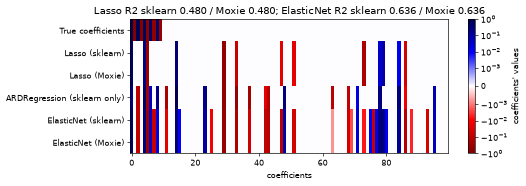

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Lasso(alpha=0.14) coef_,PASS,"(100,)","(100,)",1.09e-15,7.75e-14,"rtol=1e-08, atol=1e-10",,same cyclic coordinate-descent sweep order and duality-gap stopping rule as the pinned Cython engine; Float64 dot products differ only in BLAS summation order (family parity bound 1e-8)
Lasso(alpha=0.14) sparsity pattern (coef_ != 0),PASS,"(100,)","(100,)",,,exact,0 mismatches,
Lasso(alpha=0.14) intercept_,PASS,"(1,)","(1,)",1.11e-16,1.04e-15,"rtol=1e-08, atol=1e-10",,same cyclic coordinate-descent sweep order and duality-gap stopping rule as the pinned Cython engine; Float64 dot products differ only in BLAS summation order (family parity bound 1e-8)
Lasso(alpha=0.14) predict(X_test),PASS,"(25,)","(25,)",2.28e-15,4.39e-14,"rtol=1e-08, atol=1e-10",,same cyclic coordinate-descent sweep order and duality-gap stopping rule as the pinned Cython engine; Float64 dot products differ only in BLAS summation order (family parity bound 1e-8)
Lasso(alpha=0.14) score (R2),PASS,(),(),2.22e-16,4.63e-16,"rtol=1e-08, atol=0",,same cyclic coordinate-descent sweep order and duality-gap stopping rule as the pinned Cython engine; Float64 dot products differ only in BLAS summation order (family parity bound 1e-8)
Lasso(alpha=0.14) n_iter_,PASS,(),(),,,exact,0 mismatches,
Lasso(alpha=0.14) dual_gap_,PASS,(),(),7.11e-17,2.33e-12,"rtol=1e-08, atol=1e-12",,"same engine; the final gap is a small difference of large terms, so it gets the absolute floor 1e-12 (far below tol * ||y||^2), and n_iter_ matches exactly"
"ElasticNet(alpha=0.08, l1_ratio=0.5) coef_",PASS,"(100,)","(100,)",4.86e-16,2.29e-13,"rtol=1e-08, atol=1e-10",,same cyclic coordinate-descent sweep order and duality-gap stopping rule as the pinned Cython engine; Float64 dot products differ only in BLAS summation order (family parity bound 1e-8)
"ElasticNet(alpha=0.08, l1_ratio=0.5) sparsity pattern (coef_ != 0)",PASS,"(100,)","(100,)",,,exact,0 mismatches,
"ElasticNet(alpha=0.08, l1_ratio=0.5) intercept_",PASS,"(1,)","(1,)",1.11e-16,6.93e-16,"rtol=1e-08, atol=1e-10",,same cyclic coordinate-descent sweep order and duality-gap stopping rule as the pinned Cython engine; Float64 dot products differ only in BLAS summation order (family parity bound 1e-8)


In [6]:
mx = nb.results["l1_models"]
from matplotlib.colors import SymLogNorm
rows = {"True coefficients": true_coef, "Lasso (sklearn)": lasso.coef_, "Lasso (Moxie)": mx["lasso_coef"],
        "ARDRegression (sklearn only)": ard.coef_, "ElasticNet (sklearn)": enet.coef_, "ElasticNet (Moxie)": mx["enet_coef"]}
fig, ax = plt.subplots(figsize=(9, 3.2), dpi=60)
im = ax.imshow(np.vstack(list(rows.values())), aspect="auto", cmap="seismic_r",
               norm=SymLogNorm(linthresh=10e-4, vmin=-1, vmax=1), interpolation="nearest")
ax.set_yticks(range(len(rows)), list(rows)); ax.set_xlabel("coefficients")
fig.colorbar(im, label="coefficients' values")
ax.set_title(f"Lasso R2 sklearn {r2_score_lasso:.3f} / Moxie {mx['lasso_score'][0]:.3f}; "
             f"ElasticNet R2 sklearn {r2_score_enet:.3f} / Moxie {mx['enet_score'][0]:.3f}")
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(
    sklearn={"Lasso R2": round(sk["lasso"]["score"], 6), "Lasso nnz": int(np.sum(lasso.coef_ != 0)), "Lasso n_iter_": sk["lasso"]["n_iter"],
             "ElasticNet R2": round(sk["enet"]["score"], 6), "ElasticNet nnz": int(np.sum(enet.coef_ != 0)), "ElasticNet n_iter_": sk["enet"]["n_iter"]},
    moxie={"Lasso R2": round(float(mx["lasso_score"][0]), 6), "Lasso nnz": int(np.sum(mx["lasso_coef"] != 0)), "Lasso n_iter_": int(mx["lasso_n_iter"][0]),
           "ElasticNet R2": round(float(mx["enet_score"][0]), 6), "ElasticNet nnz": int(np.sum(mx["enet_coef"] != 0)), "ElasticNet n_iter_": int(mx["enet_n_iter"][0])})

CD = ("same cyclic coordinate-descent sweep order and duality-gap stopping rule as the pinned Cython engine; "
      "Float64 dot products differ only in BLAS summation order (family parity bound 1e-8)")
for name, label in (("lasso", "Lasso(alpha=0.14)"), ("enet", "ElasticNet(alpha=0.08, l1_ratio=0.5)")):
    nb.compare(f"{label} coef_", sk[name]["coef"], mx[f"{name}_coef"], rtol=1e-8, atol=1e-10, reason=CD)
    nb.compare(f"{label} sparsity pattern (coef_ != 0)", sk[name]["coef"] != 0, mx[f"{name}_coef"] != 0, exact=True)
    nb.compare(f"{label} intercept_", sk[name]["intercept"], mx[f"{name}_intercept"], rtol=1e-8, atol=1e-10, reason=CD)
    nb.compare(f"{label} predict(X_test)", sk[name]["pred"], mx[f"{name}_pred"], rtol=1e-8, atol=1e-10, reason=CD)
    nb.compare(f"{label} score (R2)", sk[name]["score"], mx[f"{name}_score"][0], rtol=1e-8, reason=CD)
    nb.compare(f"{label} n_iter_", sk[name]["n_iter"], mx[f"{name}_n_iter"][0], exact=True)
    nb.compare(f"{label} dual_gap_", sk[name]["gap"], mx[f"{name}_gap"][0], rtol=1e-8, atol=1e-12,
               reason="same engine; the final gap is a small difference of large terms, so it gets the absolute "
                      "floor 1e-12 (far below tol * ||y||^2), and n_iter_ matches exactly")
F32 = ("Float32 data: sklearn's Cython engine accumulates in float32 while Moxie widens dot products to Float64; "
       "family parity bound 3e-4 relative to max(1, |y|)")
for name, label in (("lasso32", "Lasso float32"), ("enet32", "ElasticNet float32")):
    nb.compare(f"{label} coef_", sk[name].coef_, mx[f"{name}_coef"], rtol=3e-4, atol=3e-4, reason=F32)
    nb.compare(f"{label} predict(X_test)", sk[name].predict(T32), mx[f"{name}_pred"], rtol=3e-4, atol=3e-4, reason=F32)
    nb.compare(f"{label} coef_ dtype", str(sk[name].coef_.dtype), str(mx[f"{name}_coef"].dtype), exact=True)
nb.compare("Lasso set_params(alpha=0.05) then refit: coef_", sk["refit"]["coef"], mx["refit_coef"], rtol=1e-8, atol=1e-10, reason=CD)
nb.compare("Lasso set_params(alpha=0.05) then refit: n_iter_", sk["refit"]["n_iter"], mx["refit_n_iter"][0], exact=True)
nb.compare("ElasticNet warm_start refit at alpha=0.04: coef_", sk["warm"]["coef"], mx["warm_coef"], rtol=1e-8, atol=1e-10, reason=CD)
nb.compare("ElasticNet warm_start refit at alpha=0.04: n_iter_", sk["warm"]["n_iter"], mx["warm_n_iter"][0], exact=True)
nb.note("ARDRegression()", "GAP", "not implemented in moxie.linear_model (coverage.md lists it as missing); the expect-fail cell shows the import error")
nb.note("seaborn heatmap", "ADAPTED", "drawn with matplotlib imshow (seaborn not installed); same SymLogNorm and colormap")
nb.note("intercept_, n_iter_, dual_gap_", "ADAPTED", "always arrays/lists, one entry per target (elastic_net/docs/api.md)")
nb.report()
nb.assert_parity()